<div dir="rtl">

# التعرّف على أفعال التجميع من الهيكل العظمي — تجارب داتاسيت HA4M

**السؤال:** هل نقدر نعرف الشخص بيعمل أنهي خطوة من خطوات التجميع، **فريم بفريم في فيديو متصل**، من **الهيكل العظمي بس** (من غير الصورة)؟
وهل الموديل اللي اتدرّب على هيكل **Kinect** هيشتغل لما ندّيله هيكل من **كاميرا عادية (YOLO)**؟

## الخلاصة في دقيقة

| | test: 8 أشخاص ما اتدرّبش عليهم (هيكل Kinect) | فيديو V001 من الكاميرا (هيكل YOLO) |
|---|---|---|
| تخمين عشوائي (13 فئة) | 7.7% | 7.7% |
| دايماً أكبر فئة | ~24% | — |
| **FastDTW** (من غير تدريب، خط أساس) | ~40% | 15% – 39% |
| **BiLSTM** — نقطة البداية | 73.3% | 37.8% |
| **أحسن نتيجة: A: LSTM صغير + الجسم العلوي + تدريب بضجيج YOLO** | **76.5%** | **68.9%** |

1. **الـ deep learning أحسن بكتير من FastDTW** (حوالي 75% مقابل 40% على نفس الـ test).
2. **كل موديلات الـ LSTM قريبة من بعض على Kinect** (74–77%). الـ attention ما فرقش كتير، والموديل الكبير مش أحسن من الصغير.
3. **المشكلة الحقيقية هي الكاميرا:** نفس الموديل بينزل من ~80% (Kinect) لـ ~40% (YOLO) على نفس الفيديو.
4. **اللي حلّ جزء كبير منها:** إننا **قِسنا** شكل غلط YOLO وضفناه على بيانات التدريب (training with YOLO-like noise). ده رفع YOLO من ~40% لـ ~60–69% **من غير ما يبوّظ** نتيجة الـ test.
5. **حدود مهمة:** تقييم YOLO على **شخص واحد وفيديو واحد** (الوحيد اللي عندنا صوره)، والفرق بين الـ seeds كبير. يعني ده **مؤشر قوي، مش إثبات نهائي**.

**محتوى التقرير:** الداتا ← خط المعالجة ← طريقة التقييم ← المراحل اللي جربناها ← الموديلات ← مشكلة الكاميرا ← التجربة الكبيرة (84 تدريب + FastDTW) ← تحليل النتايج ← الأخطاء ← الفيديوهات ← الخلاصة والحدود والخطوات الجاية.

</div>

In [1]:
%matplotlib inline
import json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import Image, Video, display

DATA, FIG, VID = Path('data'), Path('figures'), Path('videos')
FIG.mkdir(exist_ok=True)
S = json.loads((DATA / 'summary.json').read_text(encoding='utf-8'))
D = np.load(DATA / 'predictions.npz')
NAMES = [x.replace('→', '->') for x in S['names']]
MODELS = S['models']
LABEL = {'lstm': 'BiLSTM', 'attn': 'BiLSTM+att', 'text': 'Text enc.', 'A: LSTM': 'A: LSTM',
         'B: temporal att': 'B: temporal', 'C: spatial att': 'C: spatial', 'D: both': 'D: both', 'fastdtw': 'FastDTW'}
CONDS = ['full_clean', 'full_noise', 'upper_clean', 'upper_noise']
CCOL = {'full_clean': '#9ecae1', 'full_noise': '#3182bd', 'upper_clean': '#fdae6b', 'upper_noise': '#e6550d'}
# نفس ألوان الفيديوهات (BGR في OpenCV ← RGB هنا)
BGR = [(230, 120, 40), (60, 180, 75), (255, 200, 0), (180, 60, 200), (0, 140, 255), (90, 90, 230), (200, 200, 60),
       (40, 200, 200), (140, 100, 50), (120, 220, 120), (220, 90, 160), (60, 60, 180), (150, 150, 150)]
CMAP = ListedColormap([(r / 255, g / 255, b / 255) for b, g, r in BGR])

def load_run(m, c):
    if m == 'fastdtw':
        return None if c.endswith('noise') else json.loads((DATA / f'run_all_{c.split("_")[0]}_dtw.json').read_text())['fastdtw']
    return json.loads((DATA / f'run_all_{c}.json').read_text())[m]

R = {(m, c): load_run(m, c) for m in MODELS for c in CONDS}
R = {k: v for k, v in R.items() if v}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 10})
save = lambda name: plt.savefig(FIG / f'{name}.png', bbox_inches='tight', dpi=150)
n_sub = sum(len(v) for v in S['subjects'].values())
print(f"{S['n_videos']} videos | {n_sub} people | {S['n_frames']:,} labeled frames @30fps = {S['n_frames']/30/3600:.1f} hours")
print(f"{len(R)} experiment configs, {sum(len(v['ktest']) for v in R.values())} trained/evaluated runs")

217 videos | 41 people | 639,568 labeled frames @30fps = 5.9 hours
30 experiment configs, 90 trained/evaluated runs


<div dir="rtl">

## 1. الداتاسيت: HA4M

**HA4M** (Human Action for Manufacturing — Cicirelli et al., *Scientific Data*, 2022): ناس بيجمّعوا **علبة تروس كوكبية (epicyclic gear train)** على ترابيزة، ومتصوّرين بكاميرا **Azure Kinect**.

- عندنا **217 فيديو** من **41 شخص**، وكل فريم عليه لابل (أنهي خطوة بتتعمل دلوقتي) — يعني الفيديو **متصل** مش مقطّع مقاطع.
- الكاميرا بتدّي **هيكل 3D بـ 32 مفصل** من حساس العمق، 30 فريم في الثانية.
- الصور الملونة حجمها ضخم (~12 جيجا للفيديو الواحد)، فنزّلنا صور **فيديو واحد بس (V001 — الشخص 1)** عشان نجرّب عليه YOLO.

**الأفعال (12 خطوة + "مفيش فعل"):**

| # | الفعل | المعنى |
|---|---|---|
| 1 | carrier | يمسك الـ carrier ويحطه على الترابيزة |
| 2 | gear bearings | يركّب 3 رولمان بلي |
| 3 | planet gears | يركّب 3 تروس كوكبية على الـ carrier |
| 4 | carrier shaft | يدخّل عمود الـ carrier |
| 5 | sun shaft | يدخّل عمود الترس الشمسي |
| 6 | sun gear | يركّب الترس الشمسي |
| 7 | sun gear bearing | يركّب رولمان الترس الشمسي |
| 8 | ring gear | يركّب الترس الحلقي |
| 9 | block2→block1 | يرفع البلوك 2 ويحطه على البلوك 1 |
| 10 | cover | يركّب الغطا |
| 11 | screws | يحط مسمارين |
| 12 | allen key | يربط المسامير بمفتاح ألن |
| — | none | مفيش فعل / مش مهم |

**ملاحظات تأثّر على النتايج:** الفئات مش متساوية (block2→block1 وscrews وallen key واخدين أغلب الوقت)، وفي أفعال **شبه بعض جداً في حركة الجسم** (screws ↔ allen key، gear bearings ↔ planet gears، sun gear ↔ sun gear bearing) — الفرق بينهم في **القطعة اللي في الإيد**، والهيكل مش شايف القطعة.

</div>

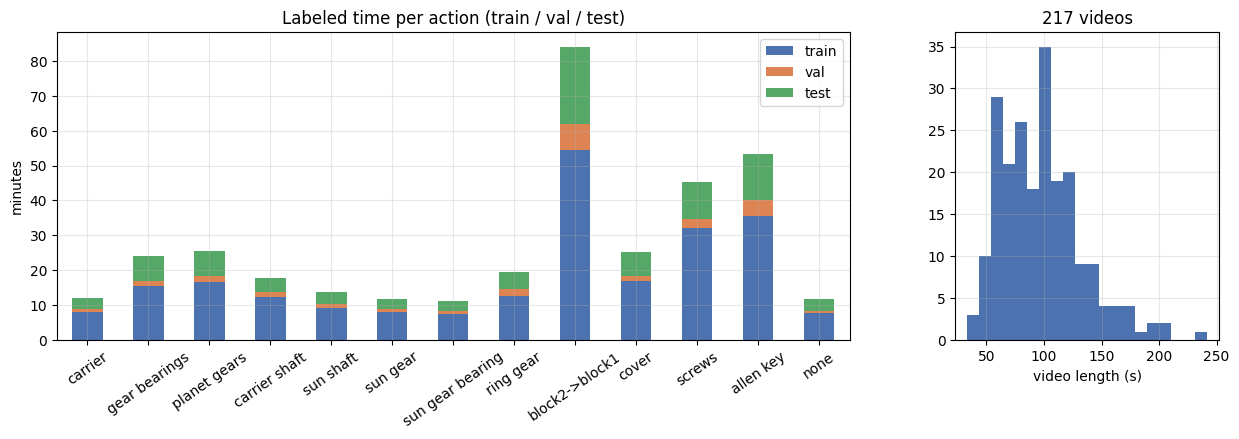

,carrier,gear bearings,planet gears,carrier shaft,sun shaft,sun gear,sun gear bearing,ring gear,block2->block1,cover,screws,allen key,none
minutes,12.1,24.0,25.5,17.9,13.7,11.9,11.3,19.5,84.1,25.2,45.3,53.3,11.7
% of frames,3.4,6.7,7.2,5.0,3.9,3.3,3.2,5.5,23.7,7.1,12.7,15.0,3.3


In [2]:
fpc = pd.DataFrame(S['frames_per_class'], index=NAMES)
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [3, 1]})
(fpc / 30 / 60).plot.bar(ax=ax[0], stacked=True, color=['#4c72b0', '#dd8452', '#55a868'], rot=35)
ax[0].set_ylabel('minutes'); ax[0].set_title('Labeled time per action (train / val / test)')
ax[1].hist(S['video_len_s'], bins=20, color='#4c72b0'); ax[1].set_xlabel('video length (s)'); ax[1].set_title(f"{S['n_videos']} videos")
save('01_dataset'); plt.show()
tot = fpc.sum(axis=1)
display(pd.DataFrame({'minutes': tot / 1800, '% of frames': 100 * tot / tot.sum()}).round(1).T)

<div dir="rtl">

صورة من كل فعل (من فيديو V001):

</div>

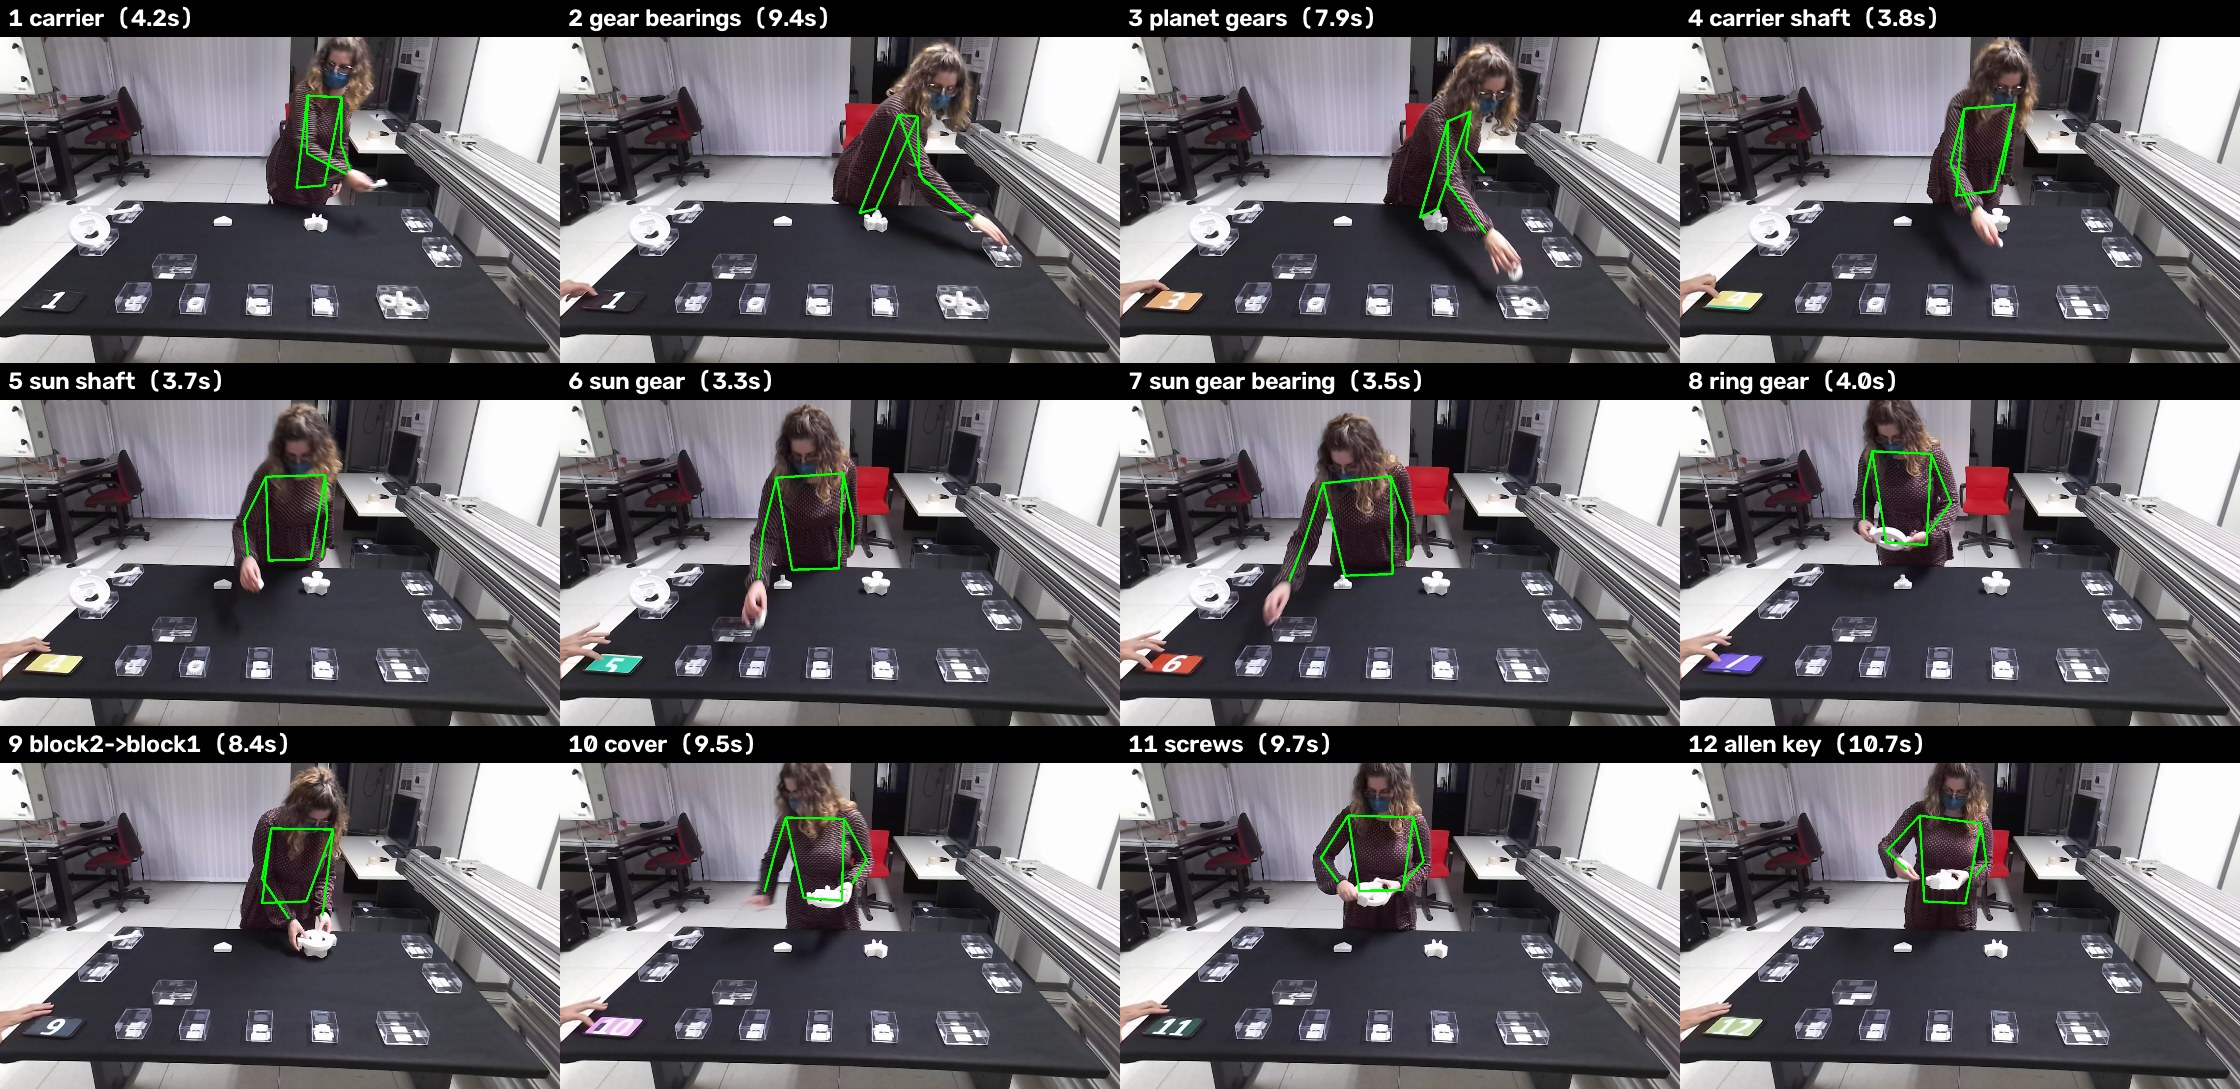

In [3]:
display(Image(filename=str(DATA / 'actions_sheet.jpg'), width=1000))

<div dir="rtl">

## 2. خط المعالجة (من الهيكل للابل كل فريم)

1. **الهيكل:** من الـ 32 مفصل بتوع Kinect بناخد **الـ 17 مفصل بتوع COCO** (أنف، عينين، ودان، كتفين، كوعين، رسغين، حوض، ركب، كعوب) **2D** — لأن ده بالظبط اللي YOLO بيطلّعه من كاميرا عادية. كده نفس الموديل يقدر ياخد الاتنين.
2. **التطبيع:** نطرح منتصف الحوض ونقسم على طول الجذع ← مش مهم الشخص واقف فين ولا طوله قد إيه.
3. **النوافذ:** نافذة **3 ثواني** (90 فريم) كل **نص ثانية** (خطوة 15)، وبنختصرها لـ **30 فريم**. لابل النافذة = أكتر لابل فيها.
4. **الموديل** بيدّي احتمالات الـ 13 فئة لكل نافذة.
5. **التنعيم:** متوسط 5 نوافذ ورا بعض، وكل فريم بياخد توقع **أقرب نافذة** ← **لابل لكل فريم**، وبنقارنه باللابل الحقيقي.

</div>

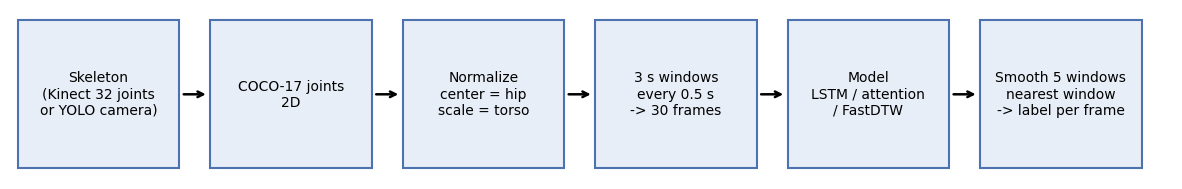

In [4]:
steps = ['Skeleton\n(Kinect 32 joints\nor YOLO camera)', 'COCO-17 joints\n2D', 'Normalize\ncenter = hip\nscale = torso',
         '3 s windows\nevery 0.5 s\n-> 30 frames', 'Model\nLSTM / attention\n/ FastDTW', 'Smooth 5 windows\nnearest window\n-> label per frame']
fig, ax = plt.subplots(figsize=(15, 2.2)); ax.axis('off')
for i, s in enumerate(steps):
    ax.add_patch(plt.Rectangle((i * 2.5, 0), 2.1, 1.4, fc='#e8eef7', ec='#4c72b0', lw=1.5))
    ax.text(i * 2.5 + 1.05, .7, s, ha='center', va='center', fontsize=10)
    if i < len(steps) - 1:
        ax.annotate('', xy=(i * 2.5 + 2.48, .7), xytext=(i * 2.5 + 2.12, .7), arrowprops=dict(arrowstyle='->', lw=1.8))
ax.set_xlim(-.1, len(steps) * 2.5); ax.set_ylim(-.1, 1.5)
save('02_pipeline'); plt.show()

<div dir="rtl">

**نفس اللحظة بعينين مختلفين:** هيكل Kinect (من حساس العمق) مقابل هيكل YOLO (من الصورة الملونة بس). YOLO بيفقد الرجلين (ورا الترابيزة) وبيهتز أكتر — ده أصل "مشكلة الكاميرا" اللي في الجزء 6.

</div>

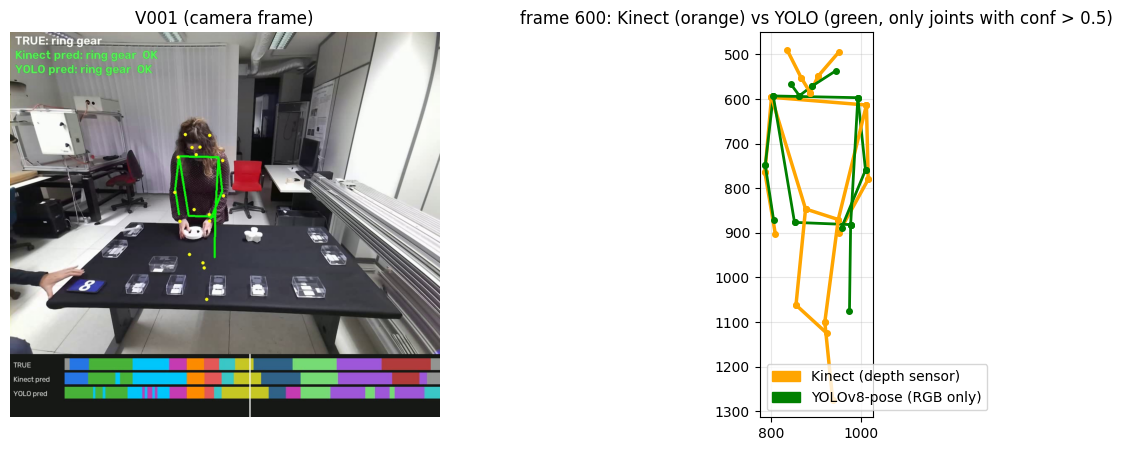

In [5]:
EDGES = [(5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]
i = 600
kin, yolo, conf = D['kin'][i], D['yolo'][i], D['conf'][i]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(plt.imread(DATA / 'V001_frame600.jpg')); ax[0].axis('off'); ax[0].set_title('V001 (camera frame)')
for a, b in EDGES:
    ax[1].plot(*kin[[a, b]].T, 'o-', c='orange', lw=2.5, ms=4)
    if conf[a] > .5 and conf[b] > .5:
        ax[1].plot(*yolo[[a, b]].T, 'o-', c='green', lw=2, ms=4)
ax[1].invert_yaxis(); ax[1].set_aspect('equal'); ax[1].set_title(f'frame {i}: Kinect (orange) vs YOLO (green, only joints with conf > 0.5)')
ax[1].legend(handles=[Patch(color='orange', label='Kinect (depth sensor)'), Patch(color='green', label='YOLOv8-pose (RGB only)')])
save('02_kinect_vs_yolo'); plt.show()

<div dir="rtl">

## 3. طريقة التقييم (عشان الأرقام تبقى أمينة)

- **التقسيم بالشخص، مش بالفيديو:** 29 شخص تدريب / 4 validation (لاختيار أحسن epoch) / **8 test**. مفيش شخص في أكتر من مجموعة، يعني الموديل **عمره ما شاف** حد من الـ test. التقسيم ثابت لكل التجارب ومحفوظ في `split.json`.
- **الشخص 1 دايماً في الـ test**، لأنه الوحيد اللي عندنا صور الفيديو بتاعه (V001)، فهو الوحيد اللي نقدر نجرّب عليه YOLO.
- **التدريب** على النوافذ "النضيفة" بس (80% من فريماتها فعل واحد) — **الاختبار على كل النوافذ** بما فيها لحظات الانتقال من فعل لفعل (الأصعب).
- **المقياس:** دقة لكل فريم (frame accuracy) على كل فريمات الفيديوهات المتصلة.
- **V001:** النص الأول من الفيديو استخدمناه **نقيس منه** غلط YOLO (الجزء 6)، فالـ **النص التاني بس** هو اللي بنقيّم عليه — عشان مانغشّش.
- **3 seeds:** كل تجربة اتدرّبت 3 مرات ببداية عشوائية مختلفة، والرقم = المتوسط (والنقط في الرسومات = كل seed لوحده).

</div>

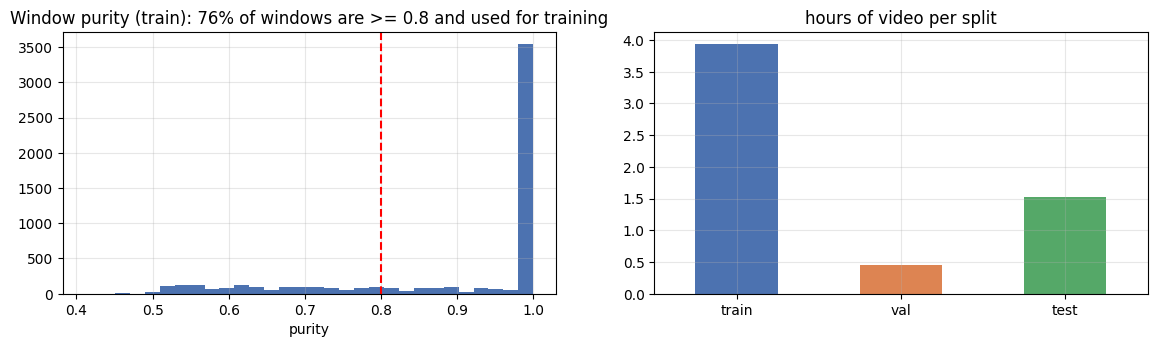

,people,videos,frames,hours
train,29,143,424749,3.93
val,4,18,49136,0.45
test,8,56,165683,1.53


test people: [1, 6, 12, 17, 22, 24, 27, 30]
chance = 7.7% | always predicting the biggest class (block2->block1) = 24.1%
windows: train 21,036 (pure) | val 2,370 | test 10,741 (all)


In [6]:
pur = np.array(S['purity_all_train'])
sp = pd.DataFrame({'people': [len(S['subjects'][s]) for s in ('train', 'val', 'test')],
                   'videos': [S['videos'][s] for s in ('train', 'val', 'test')],
                   'frames': [sum(S['frames_per_class'][s]) for s in ('train', 'val', 'test')]}, index=['train', 'val', 'test'])
sp['hours'] = (sp.frames / 30 / 3600).round(2)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
ax[0].hist(pur, bins=30, color='#4c72b0'); ax[0].axvline(.8, c='r', ls='--')
ax[0].set_title(f'Window purity (train): {100*(pur>=.8).mean():.0f}% of windows are >= 0.8 and used for training'); ax[0].set_xlabel('purity')
sp.hours.plot.bar(ax=ax[1], color=['#4c72b0', '#dd8452', '#55a868'], rot=0); ax[1].set_title('hours of video per split')
save('03_split'); plt.show()
display(sp)
te = np.array(S['frames_per_class']['test'])
print('test people:', S['subjects']['test'])
print(f'chance = {100/13:.1f}% | always predicting the biggest class ({NAMES[te.argmax()]}) = {100*te.max()/te.sum():.1f}%')
print(f"windows: train {S['windows']['train']:,} (pure) | val {S['windows']['val']:,} | test {S['windows']['test_all']:,} (all)")

<div dir="rtl">

## 4. المراحل اللي مشينا فيها (بالترتيب)

| المرحلة | السؤال | اللي حصل | القرار |
|---|---|---|---|
| 1 | أنهي نسخة من الهيكل؟ | على مقاطع مقطوعة جاهزة: 17 مفصل 2D = 79.6%، 32 مفصل 2D+3D = 81.7% | نشتغل بـ **17 مفصل 2D** — بنخسر ~2% بس، وفي المقابل يشتغل مع أي كاميرا (YOLO) |
| 2 | فيديو متصل فريم بفريم؟ | BiLSTM: **73.3%** على 8 أشخاص جداد. نفس الموديل على YOLO: **31%** | المهمة المتصلة شغالة — **الكاميرا هي المشكلة** |
| 3 | أنهي موديل؟ | 3 موديلات كبيرة (BiLSTM / BiLSTM+attention / Text encoder) + 4 موديلات صغيرة (A/B/C/D بـ attention زمني ومكاني) | الصغيرة أحسن شوية (74–77% مقابل 71–73%) |
| 4 | YOLO بيمسك الشخص الصح؟ | لأ! كان بياخد **أكبر مربع** فساعات يمسك حد تاني. بقاله 2.6 مفصل واضح من 17 | صلّحنا الاختيار (أوضح نقاط + أقرب لنص الصورة) ← **12.9 مفصل واضح** |
| 5 | نقرّب Kinect من YOLO؟ | قسنا غلط YOLO لكل مفصل وضفناه وقت التدريب | YOLO اتحسن جامد، والـ test ما وقعش |
| 6 | **التجربة الكبيرة** | 7 موديلات × 4 ظروف × 3 seeds = 84 تدريب + FastDTW | الجداول في الجزء 7 و 8 |

</div>

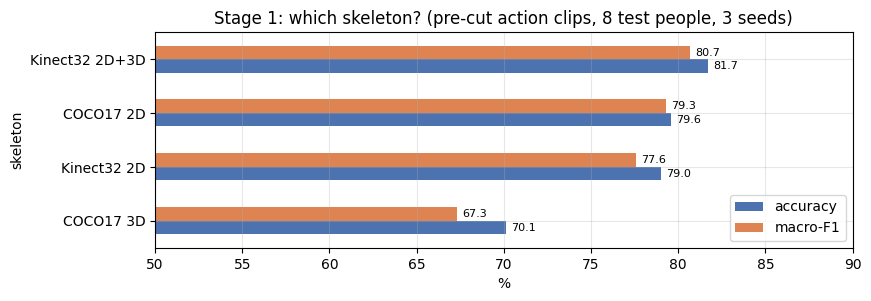

In [7]:
txt = (DATA / 'compare.txt').read_text(encoding='utf-8')
rows = re.findall(r'^([A-D])\s+(.+?)\s+دقة test\s+([\d.]+)%.*?macro-F1\s+([\d.]+)%', txt, re.M)
st1 = pd.DataFrame([(b.strip(), float(c), float(d)) for a, b, c, d in rows], columns=['skeleton', 'accuracy', 'macro-F1']).sort_values('accuracy')
ax = st1.plot.barh(x='skeleton', figsize=(9, 2.8), color=['#4c72b0', '#dd8452'])
ax.set_xlim(50, 90); ax.set_title('Stage 1: which skeleton? (pre-cut action clips, 8 test people, 3 seeds)'); ax.set_xlabel('%')
for p in ax.patches: ax.text(p.get_width() + .3, p.get_y() + p.get_height() / 2, f'{p.get_width():.1f}', va='center', fontsize=8)
save('04_stage1_skeleton'); plt.show()

<div dir="rtl">

## 5. الموديلات اللي قارناها

كلهم بياخدوا **نفس المدخل** (نافذة 30 فريم × 17 مفصل × (x, y)) ونفس التقسيم ونفس طريقة التقييم.

| الموديل | الفكرة ببساطة |
|---|---|
| **BiLSTM** | 3 طبقات LSTM في الاتجاهين (256←128←128)، والقرار من آخر حالة. أكبر موديل. |
| **BiLSTM+att** | نفس الـ BiLSTM، بس بدل آخر حالة بنعمل **متوسط موزون** لكل الفريمات (الموديل بيتعلم أنهي فريم أهم). |
| **Text enc.** | نفس شبكة مشروع الـ zero-shot: الهيكل بيتحوّل لكود، وبنقارنه بكود **وصف الفعل بالكلام** (MiniLM). هنا اتدرّب على كل الفئات، فدي مقارنة معمارية مش zero-shot. |
| **A: LSTM** | LSTM **صغيرة** (طبقة واحدة، 64)، ومدخل كل مفصل = مكانه + **سرعته**، وتدريب متوازن بين الفئات. |
| **B: temporal** | A + **attention زمني** (أنهي لحظة في الـ 3 ثواني أهم). |
| **C: spatial** | A + **attention مكاني** (أنهي مفصل أهم — مثلاً الإيدين). |
| **D: both** | A + الاتنين. |
| **FastDTW** | **من غير تدريب:** بنقارن كل نافذة بـ 15 مثال من كل فعل بـ Dynamic Time Warping، وناخد فعل أقرب واحد (1-NN). خط أساس كلاسيكي. |

</div>

In [8]:
desc = {'lstm': '3-layer BiLSTM, last state', 'attn': '3-layer BiLSTM + attention pooling', 'text': 'skeleton encoder vs MiniLM text codes',
        'A: LSTM': '1-layer LSTM(64), position+velocity, balanced sampling', 'B: temporal att': 'A + temporal attention',
        'C: spatial att': 'A + spatial (joint) attention', 'D: both': 'A + temporal + spatial attention', 'fastdtw': '1-NN FastDTW, 15 templates/class'}
display(pd.DataFrame([{'model': LABEL[m], 'what': desc[m], 'trainable parameters': f"{S['params'][m]:,}"} for m in MODELS]).set_index('model'))

,what,trainable parameters
model,,
BiLSTM,"3-layer BiLSTM, last state","1,720,333"
BiLSTM+att,3-layer BiLSTM + attention pooling,"1,720,590"
Text enc.,skeleton encoder vs MiniLM text codes,"1,815,681"
A: LSTM,"1-layer LSTM(64), position+velocity, balanced ...","35,149"
B: temporal,A + temporal attention,"37,262"
C: spatial,A + spatial (joint) attention,"35,246"
D: both,A + temporal + spatial attention,"37,359"
FastDTW,"1-NN FastDTW, 15 templates/class",0


<div dir="rtl">

## 6. مشكلة الكاميرا: من Kinect لـ YOLO

الموديل بيتدرّب على هيكل **Kinect** (عندنا منه 217 فيديو)، بس في الحقيقة هيبقى عندنا **كاميرا عادية** + **YOLOv8-pose** بيطلّع الهيكل من الصورة. الاتنين نفس الـ 17 مفصل، بس YOLO:
- **مش شايف الرجلين** (ورا الترابيزة) — الركب والكعوب بتضيع 77–100% من الوقت.
- **بيهتز** أكتر، وغلطه **متصل** من فريم للتاني (مش عشوائي).
- **كان بيمسك الشخص الغلط:** الكود القديم كان بياخد أكبر مربع في الصورة.

### 6.1 تصليح اختيار الشخص
بدل "أكبر مربع" بقينا ناخد الشخص اللي عنده **أكتر مفاصل واضحة** و**أقرب لنص الصورة**:

</div>

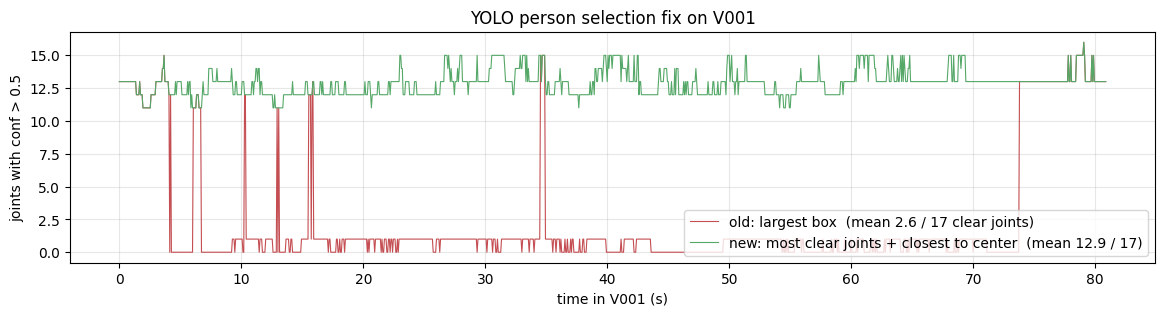

In [9]:
go, gn = (D['old_conf'] > .5).sum(1), (D['conf'] > .5).sum(1)
t = np.arange(len(gn)) / 15
plt.figure(figsize=(14, 3))
plt.plot(t, go, lw=.8, c='#c44e52', label=f'old: largest box  (mean {go.mean():.1f} / 17 clear joints)')
plt.plot(t, gn, lw=.8, c='#55a868', label=f'new: most clear joints + closest to center  (mean {gn.mean():.1f} / 17)')
plt.xlabel('time in V001 (s)'); plt.ylabel('joints with conf > 0.5'); plt.legend(loc='lower right'); plt.title('YOLO person selection fix on V001')
save('06_person_selection'); plt.show()

<div dir="rtl">

### 6.2 قسنا غلط YOLO وعلّمنا الموديل عليه
على **النص الأول** من V001 قارنّا YOLO بـ Kinect لكل مفصل: قد إيه بيغلط (sigma)، وقد إيه الغلط متصل بين الفريمات (rho)، وقد إيه المفصل بيضيع. بعدين وقت التدريب بنضيف **نفس نوع الغلط** على بيانات Kinect (AR(1) noise + انحياز + مفاصل ضايعة)، في 80% من الأمثلة. **ده بيحصل وقت التدريب بس** — مفيش أي تغيير وقت الاختبار.

وجرّبنا كمان فكرة تانية: **"الجسم العلوي بس" (upper)** — نصفّر الركب والكعوب في التدريب والاختبار، عشان الموديل مايعتمدش على حاجة YOLO مش شايفها.

</div>

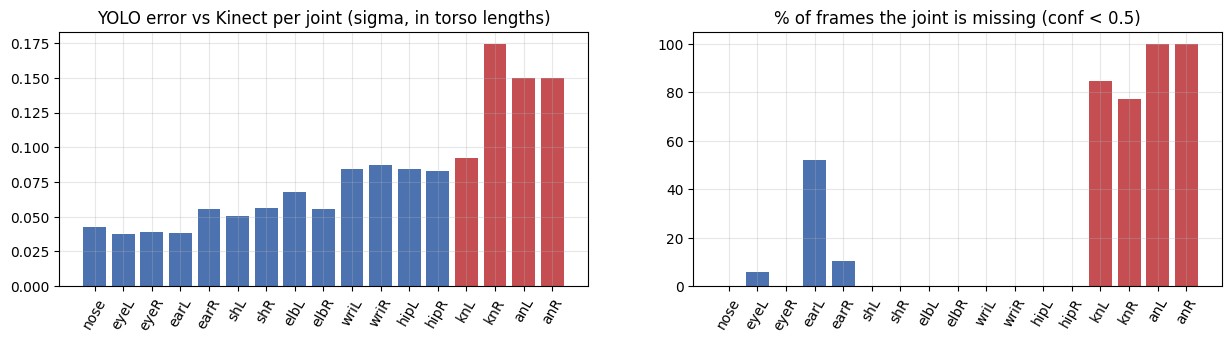

In [10]:
JN = ['nose', 'eyeL', 'eyeR', 'earL', 'earR', 'shL', 'shR', 'elbL', 'elbR', 'wriL', 'wriR', 'hipL', 'hipR', 'knL', 'knR', 'anL', 'anR']
sig, drop = np.array(S['noise']['sigma']), np.array(S['noise']['drop'])
fig, ax = plt.subplots(1, 2, figsize=(15, 3.3))
ax[0].bar(JN, sig, color=['#4c72b0'] * 13 + ['#c44e52'] * 4); ax[0].set_title('YOLO error vs Kinect per joint (sigma, in torso lengths)')
ax[1].bar(JN, 100 * drop, color=['#4c72b0'] * 13 + ['#c44e52'] * 4); ax[1].set_title('% of frames the joint is missing (conf < 0.5)')
for a in ax: a.tick_params(axis='x', rotation=60)
save('06_yolo_noise'); plt.show()

<div dir="rtl">

## 7. التجربة الكبيرة: كل الموديلات × كل الظروف

**4 ظروف تدريب** لكل موديل:

| الظرف | الهيكل | الضجيج وقت التدريب |
|---|---|---|
| `full_clean` | 17 مفصل كاملين | لأ (نقطة البداية) |
| `full_noise` | 17 مفصل كاملين | ضجيج شبه YOLO |
| `upper_clean` | الجسم العلوي بس (الركب والكعوب = صفر) | لأ |
| `upper_noise` | الجسم العلوي بس | ضجيج شبه YOLO |

**3 أعمدة تقييم:** (1) **test Kinect** = الـ 8 أشخاص الجداد، (2) **V001 Kinect** = النص التاني من فيديو الشخص 1 بهيكل Kinect، (3) **V001 YOLO** = **نفس الفريمات** بهيكل YOLO من الكاميرا.
الفرق بين (2) و(3) = **تأثير الكاميرا لوحدها** (نفس الشخص، نفس اللحظات، نفس الموديل).

FastDTW ملوش تدريب فمفيش له ضجيج — اتعمل `full` و `upper` بس.

</div>

In [11]:
rows = []
for (m, c), r in R.items():
    rows.append({'model': LABEL[m], 'condition': c, 'test Kinect (8 people)': np.mean(r['ktest']), 'V001 Kinect': np.mean(r['v_kin']),
                 'V001 YOLO': np.mean(r['v_yolo']), 'YOLO std (seeds)': np.std(r['v_yolo']),
                 'YOLO per seed': ', '.join(f'{x:.0f}' for x in r['v_yolo'])})
T = pd.DataFrame(rows)
T.to_csv(DATA / 'all_results.csv', index=False)
num = ['test Kinect (8 people)', 'V001 Kinect', 'V001 YOLO']
display(T.style.format(precision=1).background_gradient(subset=num, cmap='RdYlGn', vmin=10, vmax=85).hide(axis='index'))

model,condition,test Kinect (8 people),V001 Kinect,V001 YOLO,YOLO std (seeds),YOLO per seed
BiLSTM,full_clean,73.3,81.7,37.8,9.9,"24, 42, 47"
BiLSTM,full_noise,74.6,77.9,55.6,5.2,"62, 56, 49"
BiLSTM,upper_clean,73.5,81.1,16.9,6.4,"21, 8, 22"
BiLSTM,upper_noise,76.2,80.0,58.8,3.4,"63, 55, 58"
BiLSTM+att,full_clean,71.7,76.3,44.3,3.8,"41, 42, 50"
BiLSTM+att,full_noise,72.9,74.5,61.0,6.2,"54, 69, 60"
BiLSTM+att,upper_clean,76.7,77.5,24.7,5.6,"21, 33, 21"
BiLSTM+att,upper_noise,77.2,79.1,56.8,1.4,"56, 59, 56"
Text enc.,full_clean,71.3,76.7,33.3,12.3,"44, 16, 40"
Text enc.,full_noise,74.2,75.7,59.6,8.5,"69, 62, 48"


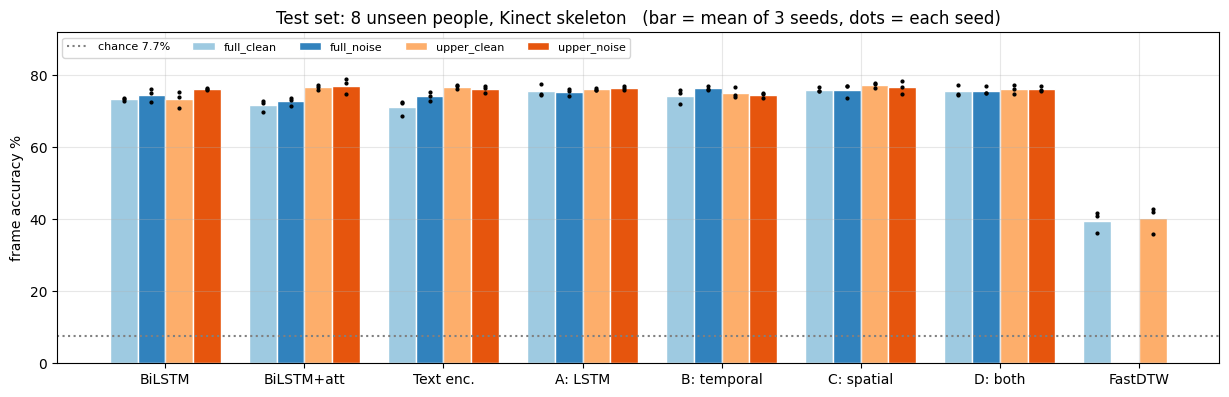

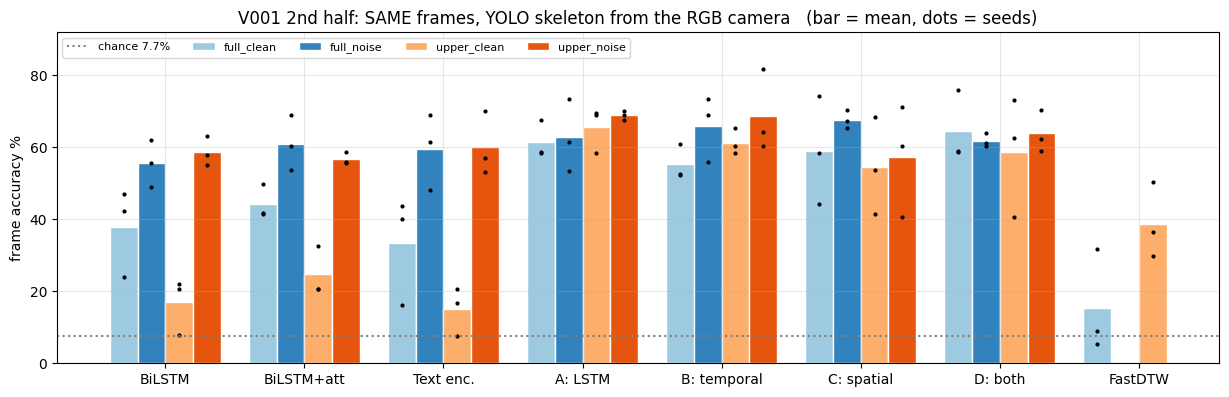

In [12]:
def grouped(metric, title, name, ylim=(0, 92)):
    fig, ax = plt.subplots(figsize=(15, 4.3)); w = .2
    for j, c in enumerate(CONDS):
        for i, m in enumerate(MODELS):
            r = R.get((m, c))
            if not r: continue
            x = i + (j - 1.5) * w
            ax.bar(x, np.mean(r[metric]), w, color=CCOL[c], label=c if i == 0 else None, edgecolor='white')
            ax.plot([x] * len(r[metric]), r[metric], 'k.', ms=4)
    ax.axhline(100 / 13, c='gray', ls=':', label='chance 7.7%')
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels([LABEL[m] for m in MODELS])
    ax.set_ylim(*ylim); ax.set_ylabel('frame accuracy %'); ax.set_title(title); ax.legend(ncol=5, fontsize=8, loc='upper left')
    save(name); plt.show()

grouped('ktest', 'Test set: 8 unseen people, Kinect skeleton   (bar = mean of 3 seeds, dots = each seed)', '07_test_kinect')
grouped('v_yolo', 'V001 2nd half: SAME frames, YOLO skeleton from the RGB camera   (bar = mean, dots = seeds)', '07_v001_yolo')

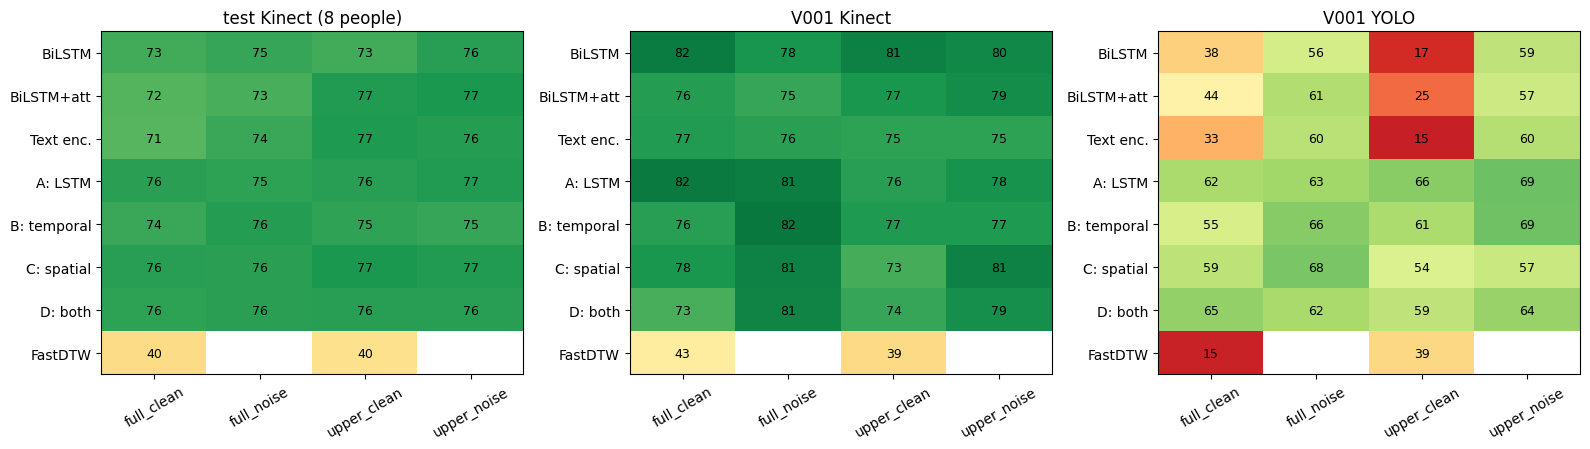

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, col in zip(ax, num):
    H = T.pivot(index='model', columns='condition', values=col).reindex([LABEL[m] for m in MODELS])[CONDS]
    a.imshow(H.values, cmap='RdYlGn', vmin=10, vmax=85, aspect='auto'); a.grid(False)
    a.set_xticks(range(4)); a.set_xticklabels(CONDS, rotation=30); a.set_yticks(range(len(H))); a.set_yticklabels(H.index)
    for i in range(H.shape[0]):
        for j in range(4):
            v = H.values[i, j]
            if not np.isnan(v): a.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=9)
    a.set_title(col)
plt.tight_layout(); save('07_heatmaps'); plt.show()

<div dir="rtl">

## 8. فهمنا إيه من الأرقام؟

### 8.1 الـ deep learning مقابل FastDTW
FastDTW (من غير تدريب) **~40%** على الـ test، وكل موديلات الـ LSTM **74–77%**. يعني التعلّم من 29 شخص أحسن بكتير من مقارنة بالأمثلة.
⚠️ المقارنة مش متطابقة 100%: FastDTW بطيء، فاستخدمنا 15 مثال لكل فعل وقيّمنا كل خامس نافذة في الـ test.

### 8.2 الموديلات على Kinect قريبة من بعض
على الـ test الفرق بين A وB وC وD **نقطة أو اتنين** — أقل من الفرق بين الـ seeds. الـ BiLSTM الكبير (حوالي 1.7 مليون باراميتر) **مش أحسن** من الـ LSTM الصغير (35 ألف). الـ attention ما أضافش فرق واضح.

### 8.3 الكاميرا هي المشكلة — والضجيج هو الحل الأقوى

</div>

model,skeleton,YOLO clean,YOLO + noise training,YOLO gain,test Kinect change
BiLSTM,full,37.8,55.6,17.8,1.3
BiLSTM,upper,16.9,58.8,41.8,2.7
BiLSTM+att,full,44.3,61.0,16.6,1.2
BiLSTM+att,upper,24.7,56.8,32.1,0.5
Text enc.,full,33.3,59.6,26.2,2.9
Text enc.,upper,15.0,60.1,45.1,-0.6
A: LSTM,full,61.6,62.8,1.2,-0.2
A: LSTM,upper,65.7,68.9,3.2,0.4
B: temporal,full,55.2,66.1,10.8,2.1
B: temporal,upper,61.3,68.8,7.5,-0.6


average YOLO gain from noise training: +15.5 points | average change on Kinect test: +0.7 points


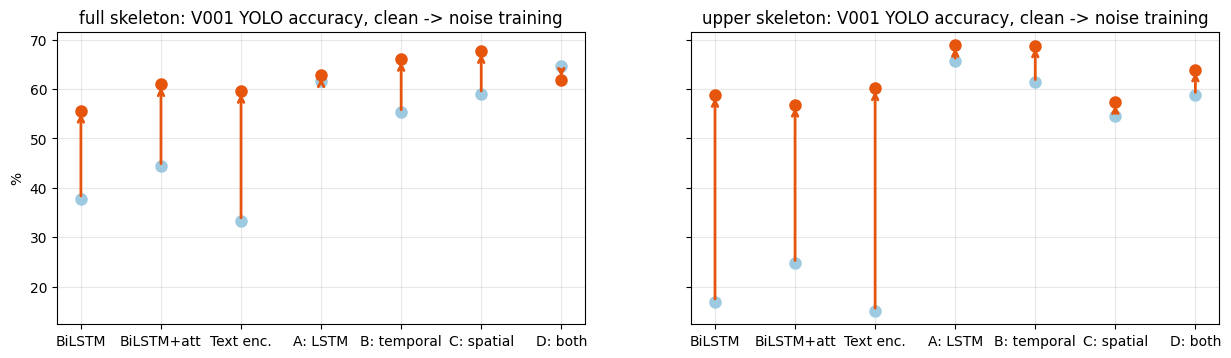

In [14]:
rows = []
for m in MODELS[:-1]:
    for body in ('full', 'upper'):
        a, b = R[(m, f'{body}_clean')], R[(m, f'{body}_noise')]
        rows.append({'model': LABEL[m], 'skeleton': body, 'YOLO clean': np.mean(a['v_yolo']), 'YOLO + noise training': np.mean(b['v_yolo']),
                     'YOLO gain': np.mean(b['v_yolo']) - np.mean(a['v_yolo']), 'test Kinect change': np.mean(b['ktest']) - np.mean(a['ktest'])})
NZ = pd.DataFrame(rows)
display(NZ.style.format(precision=1).background_gradient(subset=['YOLO gain'], cmap='Greens', vmin=0, vmax=45)
        .background_gradient(subset=['test Kinect change'], cmap='RdYlGn', vmin=-5, vmax=5).hide(axis='index'))
print(f"average YOLO gain from noise training: {NZ['YOLO gain'].mean():+.1f} points | average change on Kinect test: {NZ['test Kinect change'].mean():+.1f} points")

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for a, body in zip(ax, ('full', 'upper')):
    sub = NZ[NZ.skeleton == body]
    for k, (_, r) in enumerate(sub.iterrows()):
        a.annotate('', xy=(k, r['YOLO + noise training']), xytext=(k, r['YOLO clean']), arrowprops=dict(arrowstyle='->', color='#e6550d', lw=2))
        a.plot(k, r['YOLO clean'], 'o', c='#9ecae1', ms=8); a.plot(k, r['YOLO + noise training'], 'o', c='#e6550d', ms=8)
    a.set_xticks(range(len(sub))); a.set_xticklabels(sub.model); a.set_title(f'{body} skeleton: V001 YOLO accuracy, clean -> noise training')
ax[0].set_ylabel('%'); save('08_noise_effect'); plt.show()

<div dir="rtl">

- التدريب بضجيج YOLO **رفع دقة YOLO في كل موديل تقريباً** — الموديلات الكبيرة استفادت أكتر (كانت أضعف على YOLO من الأول).
- **التمن تقريباً صفر على الـ test** (Kinect): الدقة ما وقعتش، وأحياناً زادت شوية — الضجيج شغال كـ augmentation كمان.

### 8.4 "الجسم العلوي بس" لوحده ما نفعش

</div>

In [15]:
rows = []
for m in MODELS[:-1]:
    for nz in ('clean', 'noise'):
        a, b = R[(m, f'full_{nz}')], R[(m, f'upper_{nz}')]
        rows.append({'model': LABEL[m], 'training': nz, 'YOLO full': np.mean(a['v_yolo']), 'YOLO upper': np.mean(b['v_yolo']),
                     'YOLO change': np.mean(b['v_yolo']) - np.mean(a['v_yolo']), 'test change': np.mean(b['ktest']) - np.mean(a['ktest'])})
UP = pd.DataFrame(rows)
display(UP.style.format(precision=1).background_gradient(subset=['YOLO change'], cmap='RdYlGn', vmin=-25, vmax=25).hide(axis='index'))

model,training,YOLO full,YOLO upper,YOLO change,test change
BiLSTM,clean,37.8,16.9,-20.9,0.2
BiLSTM,noise,55.6,58.8,3.2,1.6
BiLSTM+att,clean,44.3,24.7,-19.6,5.0
BiLSTM+att,noise,61.0,56.8,-4.2,4.3
Text enc.,clean,33.3,15.0,-18.3,5.6
Text enc.,noise,59.6,60.1,0.5,2.1
A: LSTM,clean,61.6,65.7,4.1,0.5
A: LSTM,noise,62.8,68.9,6.2,1.0
B: temporal,clean,55.2,61.3,6.1,0.9
B: temporal,noise,66.1,68.8,2.7,-1.8


<div dir="rtl">

- كانت الفرضية: "YOLO مش شايف الرجلين، فلو شيلناهم الفجوة هتقفل". **الأرقام قالت لأ:** من غير ضجيج، الجسم العلوي **بوّظ** الموديلات الكبيرة على YOLO (BiLSTM نزل لـ 17%، Text لـ 15%). الموديلات الصغيرة (A وB) استفادت.
- **مع الضجيج** الجسم العلوي بقى كويس، وأحسن نتيجتين على YOLO الاتنين `upper_noise`: **A = 68.9%** (ثابتة: 68, 69, 70) و **B = 68.8%** (مش ثابتة: 64, 60, 82).
- الخلاصة: **الرجلين مش هما السبب الأساسي** — السبب الأكبر هو **شكل غلط YOLO** (اهتزاز وانحياز) في الجسم كله.

### 8.5 لسه في فجوة

</div>

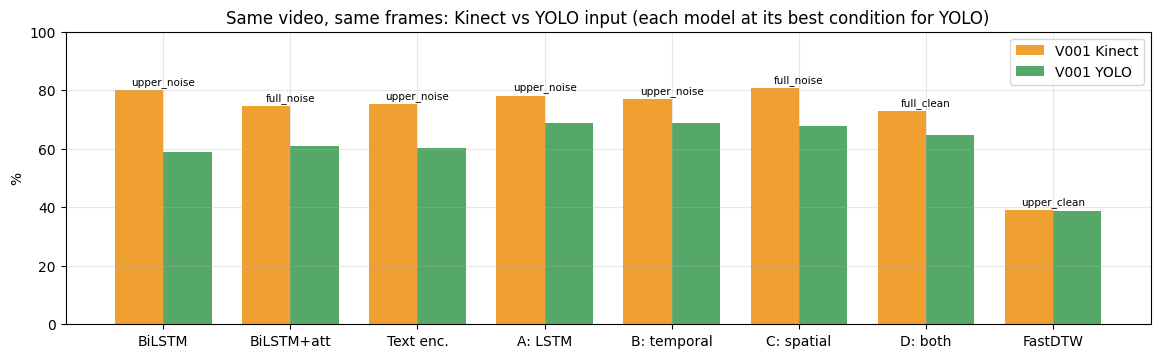

In [16]:
best = [(m, max((c for c in CONDS if (m, c) in R), key=lambda c: np.mean(R[(m, c)]['v_yolo']))) for m in MODELS]
fig, ax = plt.subplots(figsize=(14, 3.8)); w = .38
for i, (m, c) in enumerate(best):
    r = R[(m, c)]
    ax.bar(i - w / 2, np.mean(r['v_kin']), w, color='#f0a030', label='V001 Kinect' if i == 0 else None)
    ax.bar(i + w / 2, np.mean(r['v_yolo']), w, color='#55a868', label='V001 YOLO' if i == 0 else None)
    ax.text(i, max(np.mean(r['v_kin']), np.mean(r['v_yolo'])) + 2, c, ha='center', fontsize=7.5)
ax.set_xticks(range(len(best))); ax.set_xticklabels([LABEL[m] for m, _ in best]); ax.set_ylim(0, 100); ax.legend()
ax.set_title("Same video, same frames: Kinect vs YOLO input (each model at its best condition for YOLO)"); ax.set_ylabel('%')
save('08_gap'); plt.show()

<div dir="rtl">

حتى أحسن موديل: ~78% بـ Kinect مقابل ~69% بـ YOLO على **نفس الفريمات** — فاضل حوالي 10 نقط بسبب الكاميرا.

### 8.6 الـ seeds بتفرق جداً على YOLO

</div>

In [17]:
sd = T.groupby('model', sort=False)[['YOLO std (seeds)']].mean()
sd['test std (seeds)'] = [np.mean([np.std(R[(m, c)]['ktest']) for c in CONDS if (m, c) in R]) for m in MODELS]
display(sd.round(1).T)

model,BiLSTM,BiLSTM+att,Text enc.,A: LSTM,B: temporal,C: spatial,D: both,FastDTW
YOLO std (seeds),6.2,4.3,8.4,4.6,5.9,9.5,7.0,10.1
test std (seeds),1.0,1.2,1.0,0.7,1.0,1.1,1.0,2.8


<div dir="rtl">

على الـ test (8 أشخاص، ~165 ألف فريم) الاختلاف بين الـ seeds **حوالي نقطة**. على YOLO (فيديو واحد، ~600 فريم) ممكن يوصل **أكتر من 20 نقطة** في نفس الإعداد. عشان كده **لازم نقارن بمتوسط seeds**، ونحتاج فيديوهات YOLO أكتر عشان الأرقام تثبت.

</div>

<div dir="rtl">

## 9. الموديل بيغلط في إيه؟ (أحسن وصفة: A: LSTM + upper + noise، seed 0، على الـ 8 أشخاص)

</div>

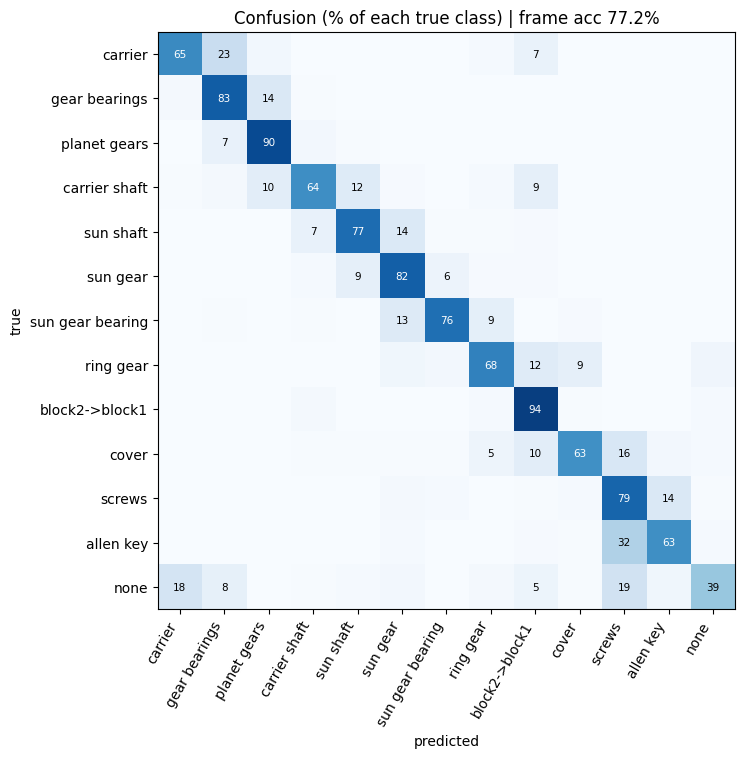

most confused (true -> predicted):
          allen key -> screws            32% of its frames
            carrier -> gear bearings     23% of its frames
               none -> screws            19% of its frames
               none -> carrier           18% of its frames
              cover -> screws            16% of its frames
      gear bearings -> planet gears      14% of its frames


,BiLSTM,BiLSTM+att,Text enc.,A: LSTM,B: temporal,C: spatial,D: both
carrier,58,64,64,65,64,56,76
gear bearings,82,79,82,83,84,87,83
planet gears,89,91,82,90,87,85,88
carrier shaft,60,68,52,64,68,62,65
sun shaft,71,78,89,77,70,85,81
sun gear,67,56,53,82,79,60,58
sun gear bearing,50,59,51,76,78,78,82
ring gear,86,85,82,68,86,82,79
block2->block1,98,97,97,94,86,89,92
cover,52,64,57,63,72,70,71


In [18]:
cm = D['A: LSTM|upper_noise|cm'].astype(float)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
for i in range(13):
    for j in range(13):
        if cmn[i, j] >= .05: ax.text(j, i, f'{100*cmn[i,j]:.0f}', ha='center', va='center', fontsize=7.5, color='white' if cmn[i, j] > .5 else 'black')
ax.set_xticks(range(13)); ax.set_xticklabels(NAMES, rotation=60, ha='right'); ax.set_yticks(range(13)); ax.set_yticklabels(NAMES)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Confusion (% of each true class) | frame acc {100*np.trace(cm)/cm.sum():.1f}%')
save('09_confusion'); plt.show()
pairs = sorted(((cmn[i, j], i, j) for i in range(13) for j in range(13) if i != j), reverse=True)[:6]
print('most confused (true -> predicted):'); [print(f'  {NAMES[i]:>17} -> {NAMES[j]:<17} {100*v:.0f}% of its frames') for v, i, j in pairs]
rec = pd.DataFrame({LABEL[m]: 100 * np.diag(D[f'{m}|upper_noise|cm']) / D[f'{m}|upper_noise|cm'].sum(1) for m in MODELS if f'{m}|upper_noise|cm' in D.files}, index=NAMES)
display(rec.round(0).style.format(precision=0).background_gradient(cmap='RdYlGn', vmin=0, vmax=100))

<div dir="rtl">

الأخطاء الكبيرة بين أفعال **حركة الجسم فيها واحدة تقريباً** والفرق في القطعة: screws ↔ allen key، gear bearings ↔ planet gears، sun gear ↔ sun gear bearing. وفئة **none** (3.7% بس من الـ test) صعبة لأنها لحظات انتقال. ده حد طبيعي لأي موديل بيشوف **الهيكل بس**.

</div>

<div dir="rtl">

## 10. الفيديوهات المتعلّمة (فولدر `videos/`)

كلهم على **V001** (الشخص 1 — في الـ test، الموديل ما شافوش). المدخل للموديل = **هيكل YOLO من الكاميرا** (أخضر)، والنقط الصفرا = Kinect للمرجعية.

| الملف | فيه إيه |
|---|---|
| [`00_all_models.mp4`](videos/00_all_models.mp4) | **كل الموديلات على نفس الفيديو** (أحسن وصفة)، توقع كل موديل دلوقتي (أخضر صح / أحمر غلط) + الدقة وهي بتتحسب + شريط زمني لكل موديل |
| [`01_lstm.mp4`](videos/01_lstm.mp4) | BiLSTM |
| [`02_bilstm_attention.mp4`](videos/02_bilstm_attention.mp4) | BiLSTM + attention |
| [`03_text_encoder.mp4`](videos/03_text_encoder.mp4) | Text encoder |
| [`04_A_lstm.mp4`](videos/04_A_lstm.mp4) | A: LSTM صغير |
| [`05_B_temporal_att.mp4`](videos/05_B_temporal_att.mp4) | B: temporal attention |
| [`06_C_spatial_att.mp4`](videos/06_C_spatial_att.mp4) | C: spatial attention |
| [`07_D_both_att.mp4`](videos/07_D_both_att.mp4) | D: الاتنين |
| [`08_fastdtw.mp4`](videos/08_fastdtw.mp4) | FastDTW |

**في فيديو كل موديل:** الفعل الحقيقي، و**قبل** (هيكل كامل من غير ضجيج) و**بعد** (جسم علوي + ضجيج YOLO) بمدخل YOLO، و"بعد" بمدخل Kinect — كل واحد بالدقة اللي بتتحسب لحظة بلحظة، وتحت 4 شرايط زمنية بالألوان (نفس الألوان = نفس الفعل). النص الأول من الفيديو **مش محسوب** (منه قسنا الضجيج).

⚠️ الفيديو = **seed واحد (0)**، فأرقامه ممكن تختلف عن الجداول (اللي هي متوسط 3 seeds). الجدول ده بيقول أرقام الـ seed اللي في الفيديو:

</div>

In [19]:
rows = []
for m in MODELS:
    b, a = S['acc'][f'{m}|full_clean'], S['acc'][f'{m}|upper_noise']
    rows.append({'model': LABEL[m], 'video file': f'videos/{m}', 'test before': b['test'], 'test after': a['test'],
                 'V001 YOLO before': b['yolo'], 'V001 YOLO after': a['yolo'], 'V001 Kinect after': a['kin']})
VT = pd.DataFrame(rows).drop(columns='video file')
display(VT.style.format(precision=1).background_gradient(subset=['V001 YOLO before', 'V001 YOLO after'], cmap='RdYlGn', vmin=10, vmax=80).hide(axis='index'))

model,test before,test after,V001 YOLO before,V001 YOLO after,V001 Kinect after
BiLSTM,73.7,76.3,24.1,63.3,79.9
BiLSTM+att,73.0,77.9,41.4,55.7,82.9
Text enc.,72.4,76.4,43.8,53.0,79.1
A: LSTM,77.7,77.2,58.5,67.7,81.9
B: temporal,75.0,75.1,52.2,64.3,75.6
C: spatial,75.7,74.7,74.3,60.3,81.9
D: both,74.7,75.8,58.8,59.0,72.2
FastDTW,41.8,43.0,31.6,36.4,33.1


<div dir="rtl">

مثال واضح على تأثير الـ seed: **C: spatial** في seed 0 جاب على YOLO "قبل" 74% و"بعد" 60%. بس على الـ 3 seeds: "قبل" = 74, 44, 58 (متوسط 59%) و"بعد" = 60, 71, 41 (متوسط 57%) — يعني الـ 74% دي حظ seed. عشان كده **القرار مبني على متوسط الـ 3 seeds** (الجزء 7)، والفيديو للتوضيح بس.

</div>

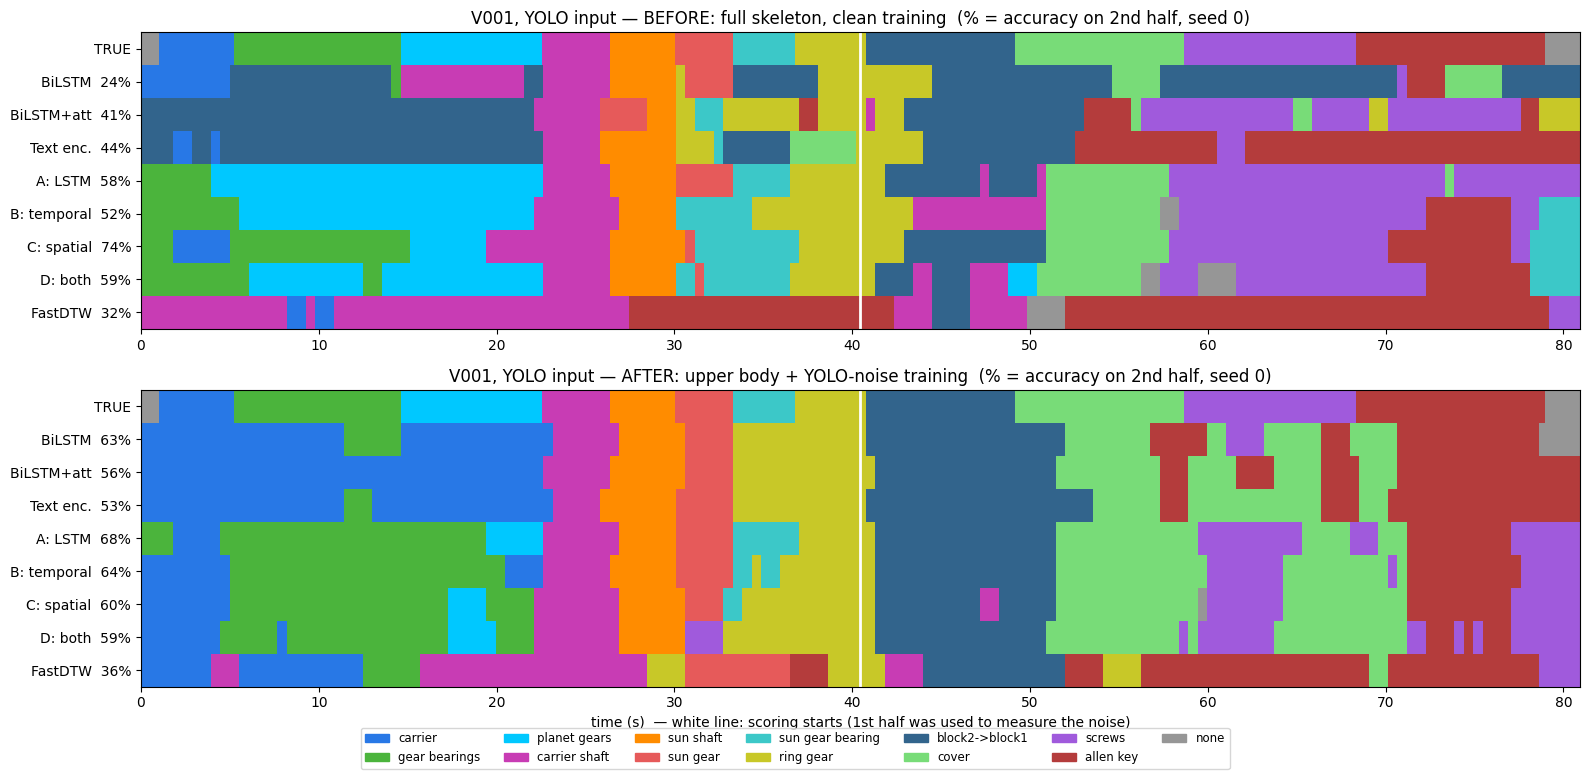

In [20]:
gt, n, half = D['gt'], S['v001']['n'], S['v001']['half']
fig, ax = plt.subplots(2, 1, figsize=(16, 7.5))
for a, (cond, title) in zip(ax, [('full_clean', 'BEFORE: full skeleton, clean training'), ('upper_noise', 'AFTER: upper body + YOLO-noise training')]):
    rows = [('TRUE', gt)] + [(f"{LABEL[m]}  {S['acc'][f'{m}|{cond}']['yolo']:.0f}%", D[f'{m}|{cond}|yolo']) for m in MODELS]
    a.imshow(np.stack([r[1] for r in rows]), cmap=CMAP, vmin=-.5, vmax=12.5, aspect='auto', interpolation='nearest', extent=(0, n / 15, len(rows) - .5, -.5))
    a.set_yticks(range(len(rows))); a.set_yticklabels([r[0] for r in rows]); a.grid(False)
    a.axvline(half / 15, c='white', lw=2); a.set_title(f'V001, YOLO input — {title}  (% = accuracy on 2nd half, seed 0)')
ax[1].set_xlabel('time (s)  — white line: scoring starts (1st half was used to measure the noise)')
fig.legend(handles=[Patch(color=CMAP(c), label=NAMES[c]) for c in range(13)], loc='lower center', ncol=7, fontsize=8.5, bbox_to_anchor=(.5, -.04))
plt.tight_layout(); save('10_timelines'); plt.show()

<div dir="rtl">

لقطة من فيديو المقارنة وفيديو موديل واحد:

</div>

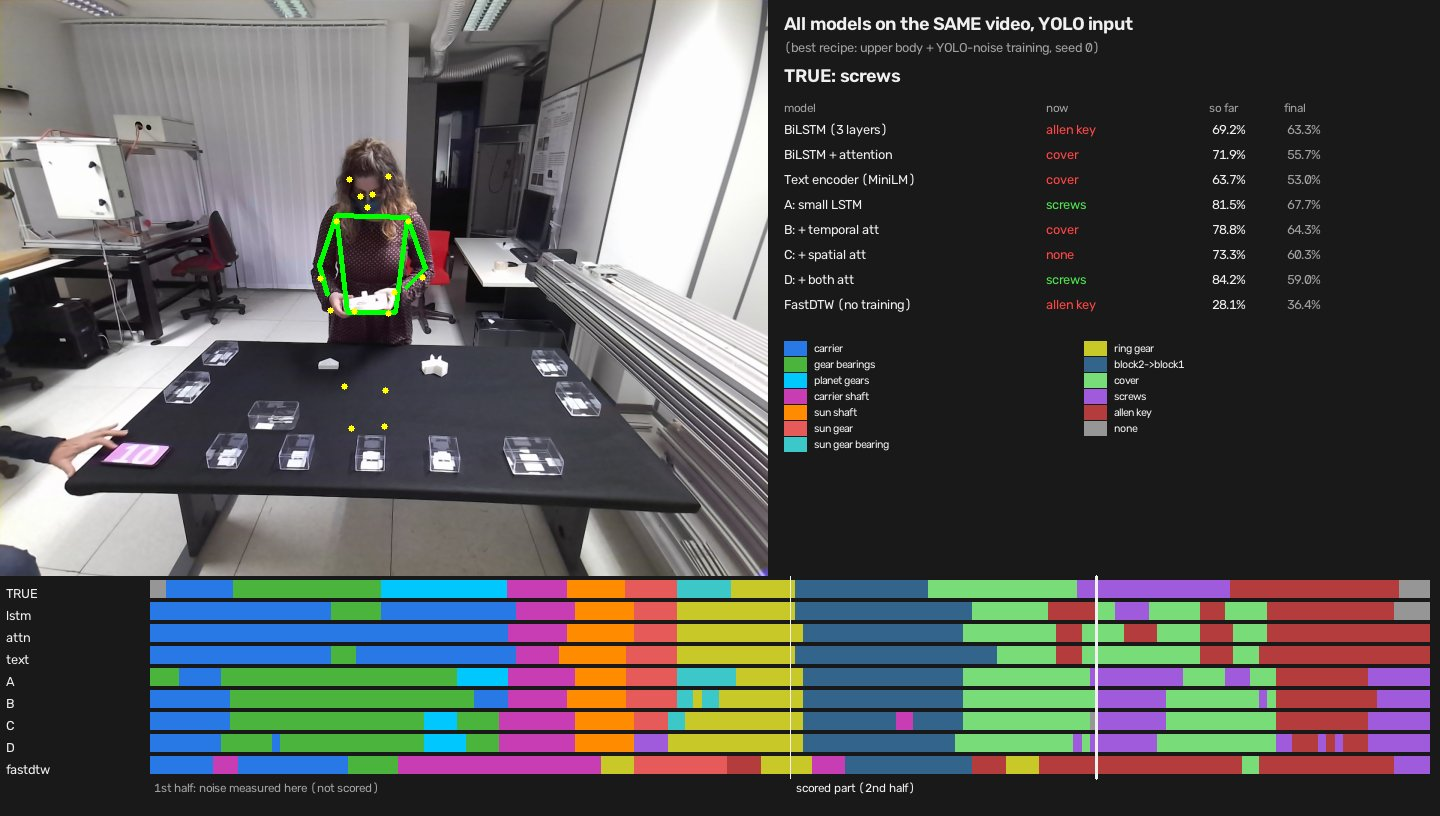

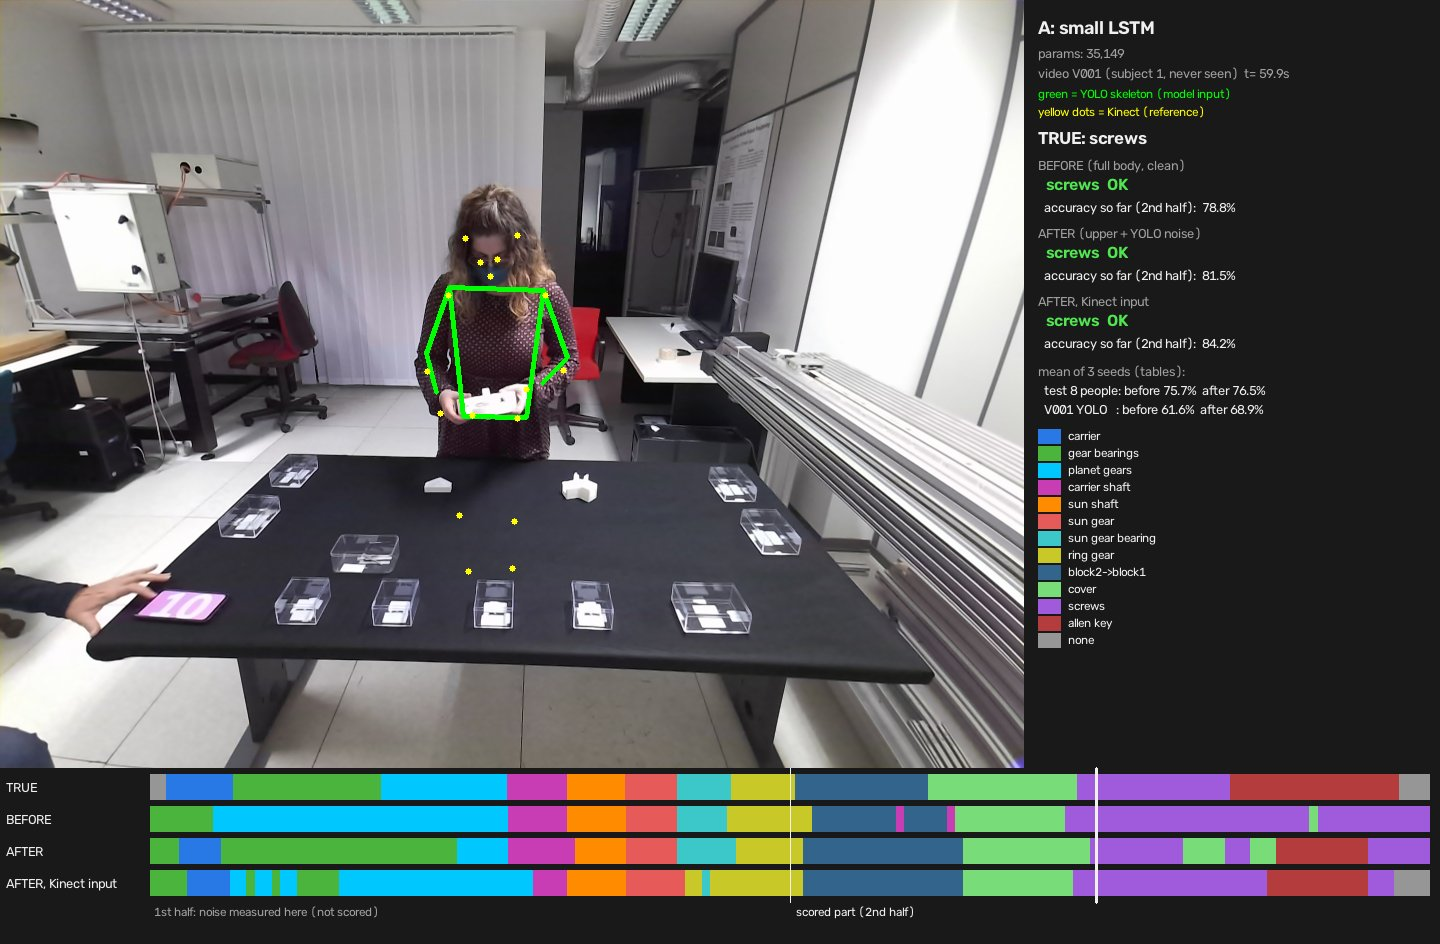

In [21]:
display(Image(filename=str(FIG / 'snap_00_all_models.jpg'), width=1000))
display(Image(filename=str(FIG / 'snap_04_A_lstm.jpg'), width=1000))
display(Video(str(VID / '00_all_models.mp4'), width=960))

<div dir="rtl">

## 11. الخلاصة

### اللي نفع ✅
- **Deep learning على الهيكل:** ~76% لكل فريم على 8 أشخاص جداد في فيديو متصل (13 فئة، التخمين 7.7%، أكبر فئة 24%). FastDTW ~40%.
- **17 مفصل 2D** كفاية: بنخسر ~2% بس عن 3D، وفي المقابل نشتغل بكاميرا عادية.
- **موديل صغير** (35 ألف باراميتر) بنفس قوة / أحسن من موديل أكبر بحوالي 50 مرة.
- **تصليح اختيار الشخص في YOLO:** من 2.6 لـ 12.9 مفصل واضح.
- **التدريب بضجيج YOLO المقاس:** أكبر تحسين على الكاميرا (BiLSTM من 38% لـ 56%، A من 62% لـ 69% مع الجسم العلوي) من غير ما الـ test يقع.

### اللي ما نفعش / ما اتأكدش ❌
- **الـ attention** (زمني / مكاني / الاتنين): ما فرقش فرق واضح عن LSTM عادي.
- **الجسم العلوي لوحده** من غير ضجيج: بوّظ الموديلات الكبيرة على YOLO.
- **الموديل الكبير:** مش أحسن، وأضعف على YOLO.
- **أفعال شبه بعض** (screws / allen key ...): الهيكل لوحده مش كفاية يفرّقهم.

### حدود لازم تتقال ⚠️
1. تقييم YOLO على **شخص واحد وفيديو واحد** (~600 فريم في النص التاني) — لأن صور باقي الفيديوهات ~12 جيجا للواحد.
2. الضجيج **متقاس من النص الأول لنفس الفيديو** — قيّمنا على النص التاني بس، بس لسه نفس الشخص ونفس الكاميرا.
3. **تقسيم واحد** (8 أشخاص test) و 3 seeds؛ الـ seeds بتفرق جامد على YOLO.
4. FastDTW اتقيّم بنسخة مختصرة (15 مثال لكل فعل، كل خامس نافذة) عشان الوقت.
5. MediaPipe ما اتقارنش بـ YOLO على الداتا دي.

### الخطوات الجاية
- صور فيديوهات أكتر لأشخاص تانيين ← تقييم YOLO على أكتر من شخص (أهم خطوة).
- Cross-validation بالأشخاص (5 folds) + seeds أكتر.
- تجربة MediaPipe مقابل YOLO على V001.
- تدريب جزء على هيكل YOLO الحقيقي (مش بس محاكاة الغلط).
- إضافة معلومة عن **القطعة في الإيد** (object detection) عشان الأفعال المتشابهة.

</div>

<div dir="rtl">

## 12. أسئلة متوقعة

**ليه الهيكل وليس الصورة؟** أخف بكتير، مش متأثر بالإضاءة والهدوم والخلفية، بيحافظ على الخصوصية، ويشتغل مع أي كاميرا لو قدرنا نطلّع منها هيكل.

**إزاي متأكدين إن الموديل ما حفظش الأشخاص؟** التقسيم بالشخص: الـ 8 أشخاص بتوع الـ test عمر الموديل ما شاف أي فريم ليهم.

**ليه الدقة على المقاطع المقطوعة (~80%) أعلى من الفيديو المتصل (~76%)؟** في الفيديو المتصل في لحظات انتقال بين الأفعال، ومش عارفين الفعل بيبدأ وبيخلص فين — وده الواقع.

**هل الضجيج "غش"؟** لأ: بيتضاف وقت التدريب بس، ومتقاس من النص الأول من الفيديو، والتقييم على النص التاني. بس صح إنه نفس الشخص — عشان كده محتاجين أشخاص أكتر.

**ليه FastDTW ضعيف؟** بيقارن شكل الحركة بس بأقرب مثال، ومفيش تعلّم لأنهي أجزاء من الحركة مهمة؛ والناس بتعمل نفس الفعل بطرق مختلفة.

**ليه مش MediaPipe؟** ما قارنّاش لسه. YOLO بيدّي نفس الـ 17 مفصل COCO اللي بنستخدمها، وبيتعامل مع أكتر من شخص. المقارنة على V001 خطوة جاية.

**أنهي موديل تختاروا؟** A: LSTM صغير + الجسم العلوي + تدريب بضجيج YOLO: أحسن وأثبت نتيجة على YOLO (68.9%، seeds 68/69/70) ونفس مستوى الأحسن على Kinect (76.5%)، وأصغر موديل.

</div>

<div dir="rtl">

## ملحق: الملفات وإزاي تعيد كل حاجة

```
ha4m_report/
├── HA4M_report.ipynb      ← التقرير ده
├── videos/                ← 9 فيديوهات H.264 (00 = مقارنة كل الموديلات)
├── figures/               ← كل الرسومات PNG (ينفع تتحط في slides)
├── data/                  ← النتايج: run_all_*.json (84 تدريب)، summary.json، predictions.npz، all_results.csv
└── build/                 ← السكريبتات اللي عملت كل ده
```

```bash
# التجربة الكبيرة (في Project/): 4 ظروف + FastDTW + تجميع
python -I ha4m/run_all.py full_clean      # وكذلك full_noise / upper_clean / upper_noise
python -I ha4m/dtw_baseline.py full       # وكذلك upper
python -I ha4m/run_all.py merge
# التقرير
python -I ha4m_report/build/make_predictions.py                      # تدريب seed 0 + حفظ التوقعات
python -I ha4m_report/build/render_videos.py <IDU001V001.zip>        # الفيديوهات
python ha4m_report/build/build_notebook.py                           # النوتبوك ده
```

</div>